# 00 · Setup and costs

Welcome to **RAG-lab**, a hands-on series that takes you from *"what is RAG?"* to a production
RAG service and an agent that decides when to search.

**In this notebook you will:**
- check that your OpenAI key works,
- make your first chat call and your first embedding call,
- see what an embedding actually is (spoiler: a long list of numbers),
- learn how the series is organised and how much it costs to run.

> Every notebook in this series is self-contained: the first three cells set everything up,
> so you can open any notebook and run it top to bottom.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT}\nChat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: D:\Github_Clones\RAG-lab
Chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: nothing to prepare for this notebook (later notebooks build or load an index here).

In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## What is RAG?

A language model only knows what was in its training data. Ask it about *your* documents
(a company handbook, a product manual, a hotel group's policies) and it either refuses or,
worse, invents a confident answer.

**Retrieval-Augmented Generation (RAG)** fixes this in two stages:

1. **Indexing (once):** split your documents into small chunks and turn each chunk into a
   vector (an *embedding*) that captures its meaning. Store the vectors.
2. **Querying (every question):** embed the question the same way, find the chunks whose vectors
   are closest, and paste those chunks into the prompt. The model answers from them.

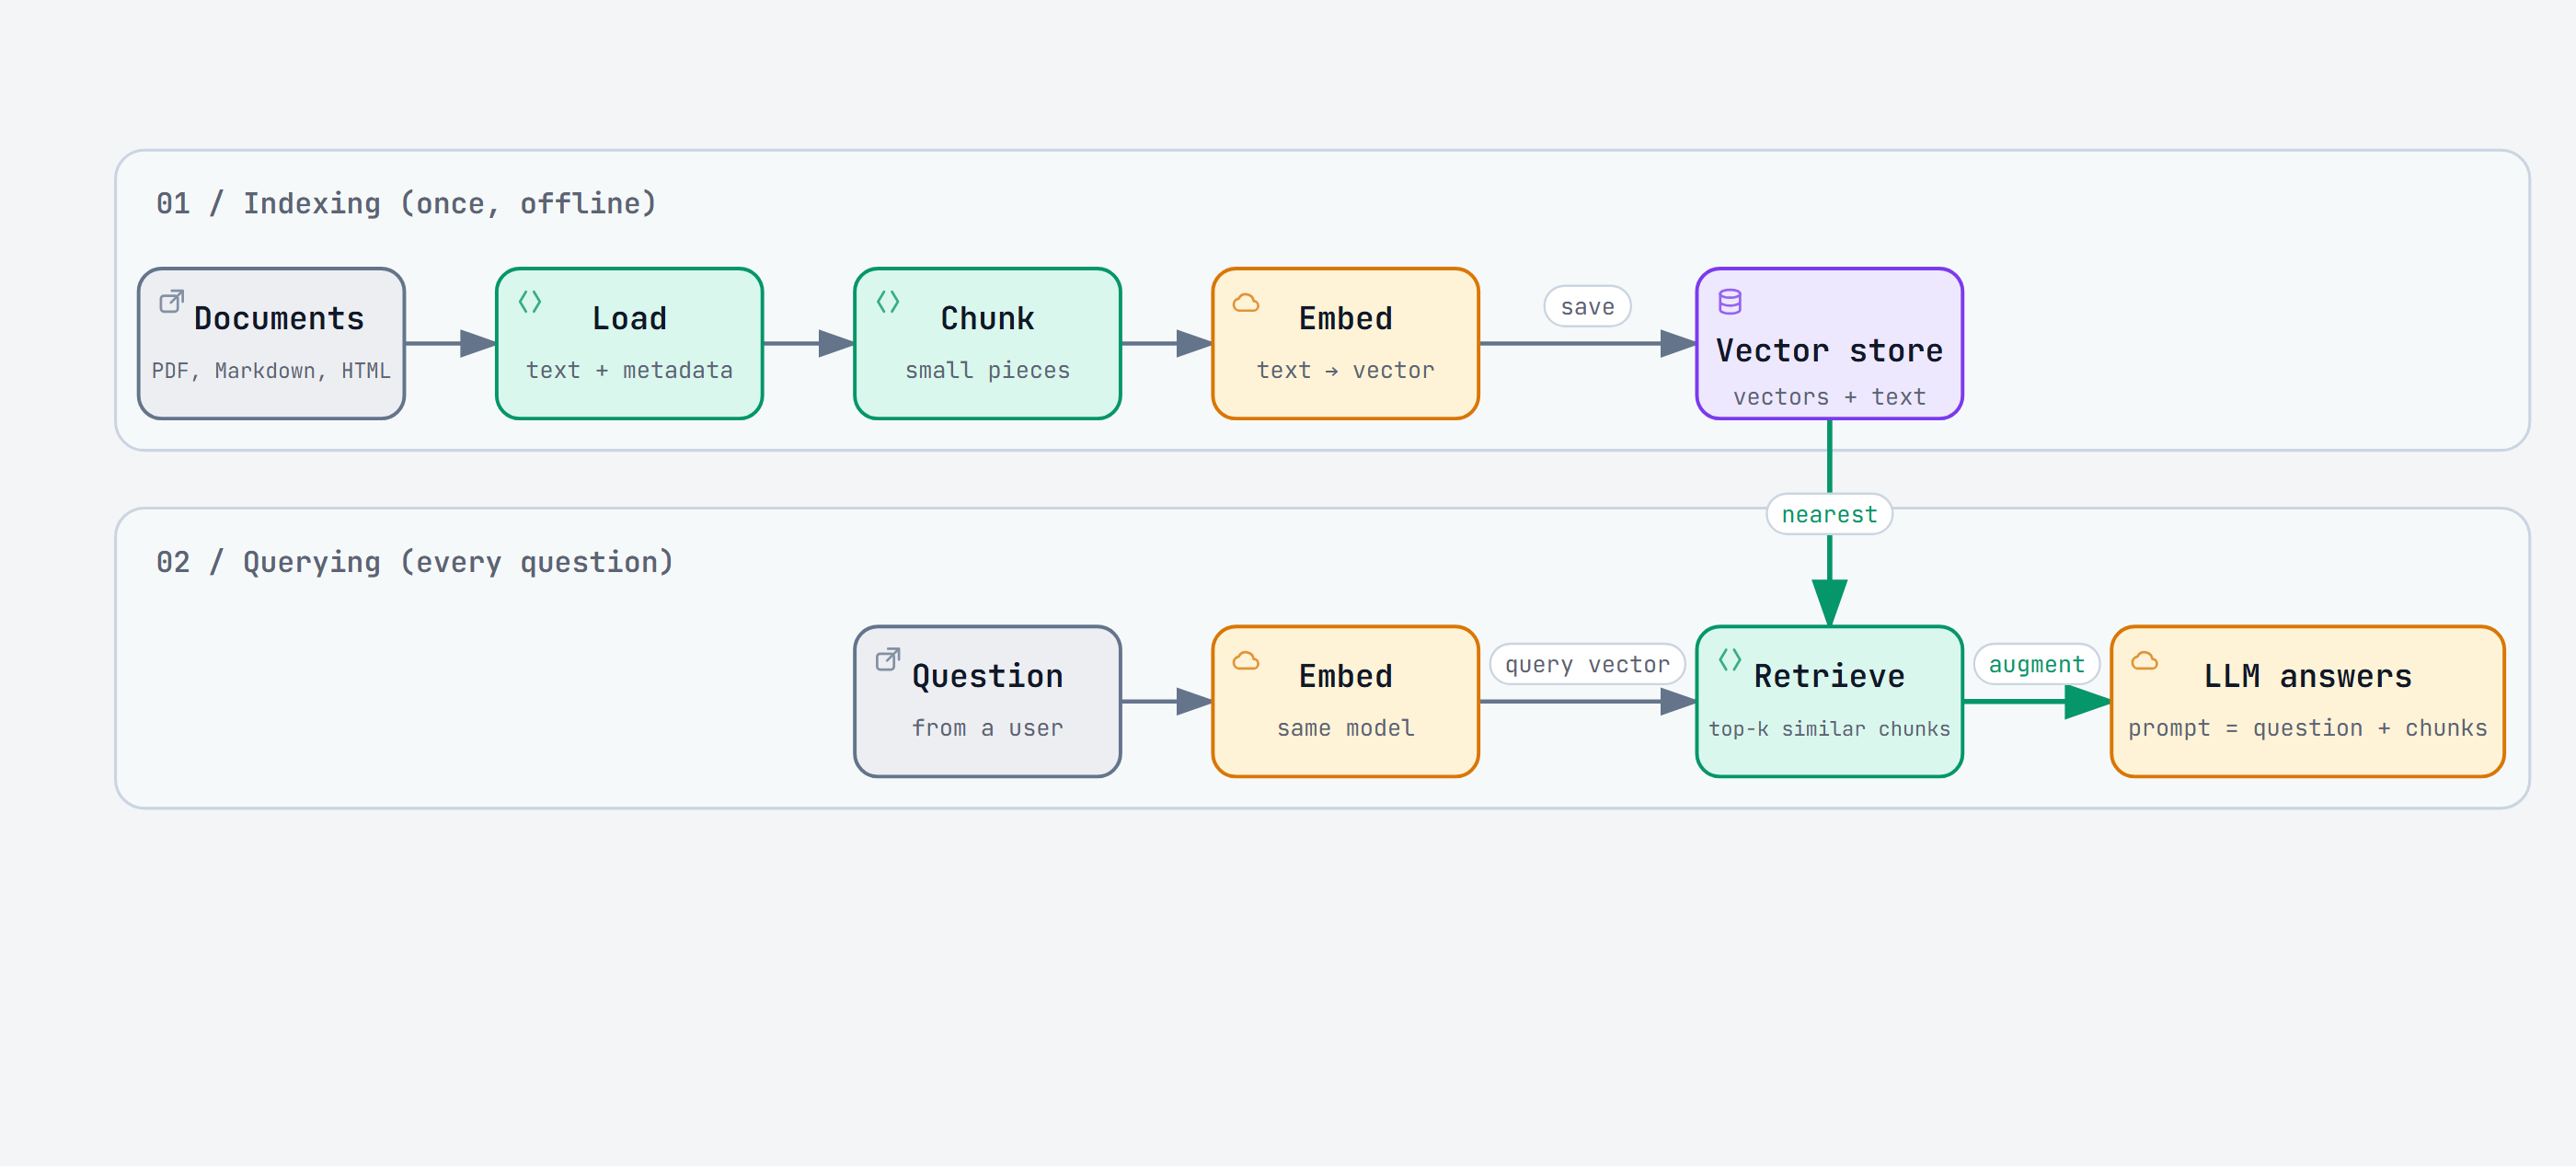

[Open interactive version](../diagrams/rag_overview.html)

In [4]:
from raglab.display import show_diagram

show_diagram("rag_overview")

## The documents we'll use

All notebooks use the documents of **Token Hotels & Resorts**, a fictional hotel group with 8
hotels on six continents. Because the company is made up, the model can't know these facts from
its training data, so any correct answer *must* come from retrieval. That makes it a fair test.

The corpus lives in `data/corpus/` and has deliberately varied formats and problems:

In [5]:
for path in sorted(settings.corpus_dir.iterdir()):
    print(f"{path.name:<32}{path.stat().st_size:>8,} bytes")

cancellation_policy_2024.md          854 bytes
cancellation_policy_2025.md        1,003 bytes
dining_guide.md                    4,424 bytes
faq.html                           2,781 bytes
guest_reviews.md                   1,334 bytes
hotel_profiles.pdf                 7,615 bytes
loyalty_program.md                 1,138 bytes
loyalty_program_reprint.md         1,189 bytes
room_rates.csv                     2,057 bytes


## Your first chat call

`raglab.llm` is the only module that talks to OpenAI. `chat()` sends one request and returns the text.

In [6]:
from raglab import llm

print(llm.chat("In one sentence, what is retrieval-augmented generation?"))

Retrieval-augmented generation (RAG) is a method where an AI retrieves relevant information from external sources and uses it to generate a more informed response.


Now ask about something the model can't know:

In [7]:
print(llm.chat("What time is check-in at the Token Kyoto hotel?"))

Check-in at Token Kyoto is typically from 3:00 PM.


Depending on the model and the day, you'll see a refusal ("I don't have information about…") or
a confident guess, sometimes about a *real* hotel with a similar name. Token Kyoto's actual check-in
time (from its documents) is 4:00 PM. Without the documents the model can't know that; the rest of
the series fixes this.

## Your first embedding

An **embedding** turns text into a vector of numbers. Texts with similar meanings get vectors
that point in similar directions. That is all retrieval needs.

In [8]:
vector = llm.embed_one("Check-in starts at 4:00 PM.")
print(f"dimensions: {len(vector)}")
print(f"first five values: {[round(v, 4) for v in vector[:5]]}")

dimensions: 1536
first five values: [-0.0271, 0.0439, -0.011, -0.0149, -0.0272]


Let's compare a few sentences. We'll use **cosine similarity**: 1.0 means "same direction",
around 0 means unrelated. (Notebook 01 explains the maths.)

In [9]:
import numpy as np

sentences = [
    "Check-in starts at 4:00 PM.",
    "You can get your room key from four in the afternoon.",
    "The restaurant serves a seven-course tasting menu.",
]
vectors = np.array(llm.embed(sentences))
unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
similarity = unit @ unit.T
for i, s in enumerate(sentences):
    print(f"{s:<58} " + "  ".join(f"{similarity[i, j]:.2f}" for j in range(len(sentences))))

Check-in starts at 4:00 PM.                                1.00  0.54  0.15
You can get your room key from four in the afternoon.      0.54  1.00  0.14
The restaurant serves a seven-course tasting menu.         0.15  0.14  1.00


The first two sentences share almost no words, yet their similarity is much higher than either
one's similarity to the restaurant sentence. Embeddings capture *meaning*, not keywords.

## Embeddings are cached

Every embedding is saved in `.cache/embeddings.sqlite`, keyed by the model and the exact text.
Re-running a notebook doesn't pay for the same embedding twice. Watch the call count:

In [10]:
before = cost.calls()
llm.embed(sentences)  # same texts as above
print(f"API calls made by that line: {cost.calls() - before}")

API calls made by that line: 0


## How much does this series cost?

The defaults are chosen to be cheap:

| Model | Used for | Price per 1M tokens (in / out) |
|---|---|---|
| `text-embedding-3-small` | embeddings | $0.02 |
| `gpt-6-luna` | chat (answers, judges) | $0.10 / $0.50 |

A default run of any notebook costs **about $0.05 or less**. `llm.estimate_cost()` lets you
check before you run something big:

In [11]:
corpus_chars = sum(p.stat().st_size for p in settings.corpus_dir.iterdir())
corpus_tokens = corpus_chars // 4  # rough rule: ~4 characters per token in English
print(f"Embedding the whole corpus once: ~${llm.estimate_cost('text-embedding-3-small', 1, corpus_tokens, 0):.5f}")
print(f"1,000 short questions answered: ~${llm.estimate_cost(settings.chat_model, 1000, 1500, 150):.2f}")

Embedding the whole corpus once: ~$0.00011
1,000 short questions answered: ~$0.23


## How the series is organised

13 notebooks in three parts. Each notebook adds a few functions to the shared **`raglab`**
package (shown under each title), and later notebooks import them.

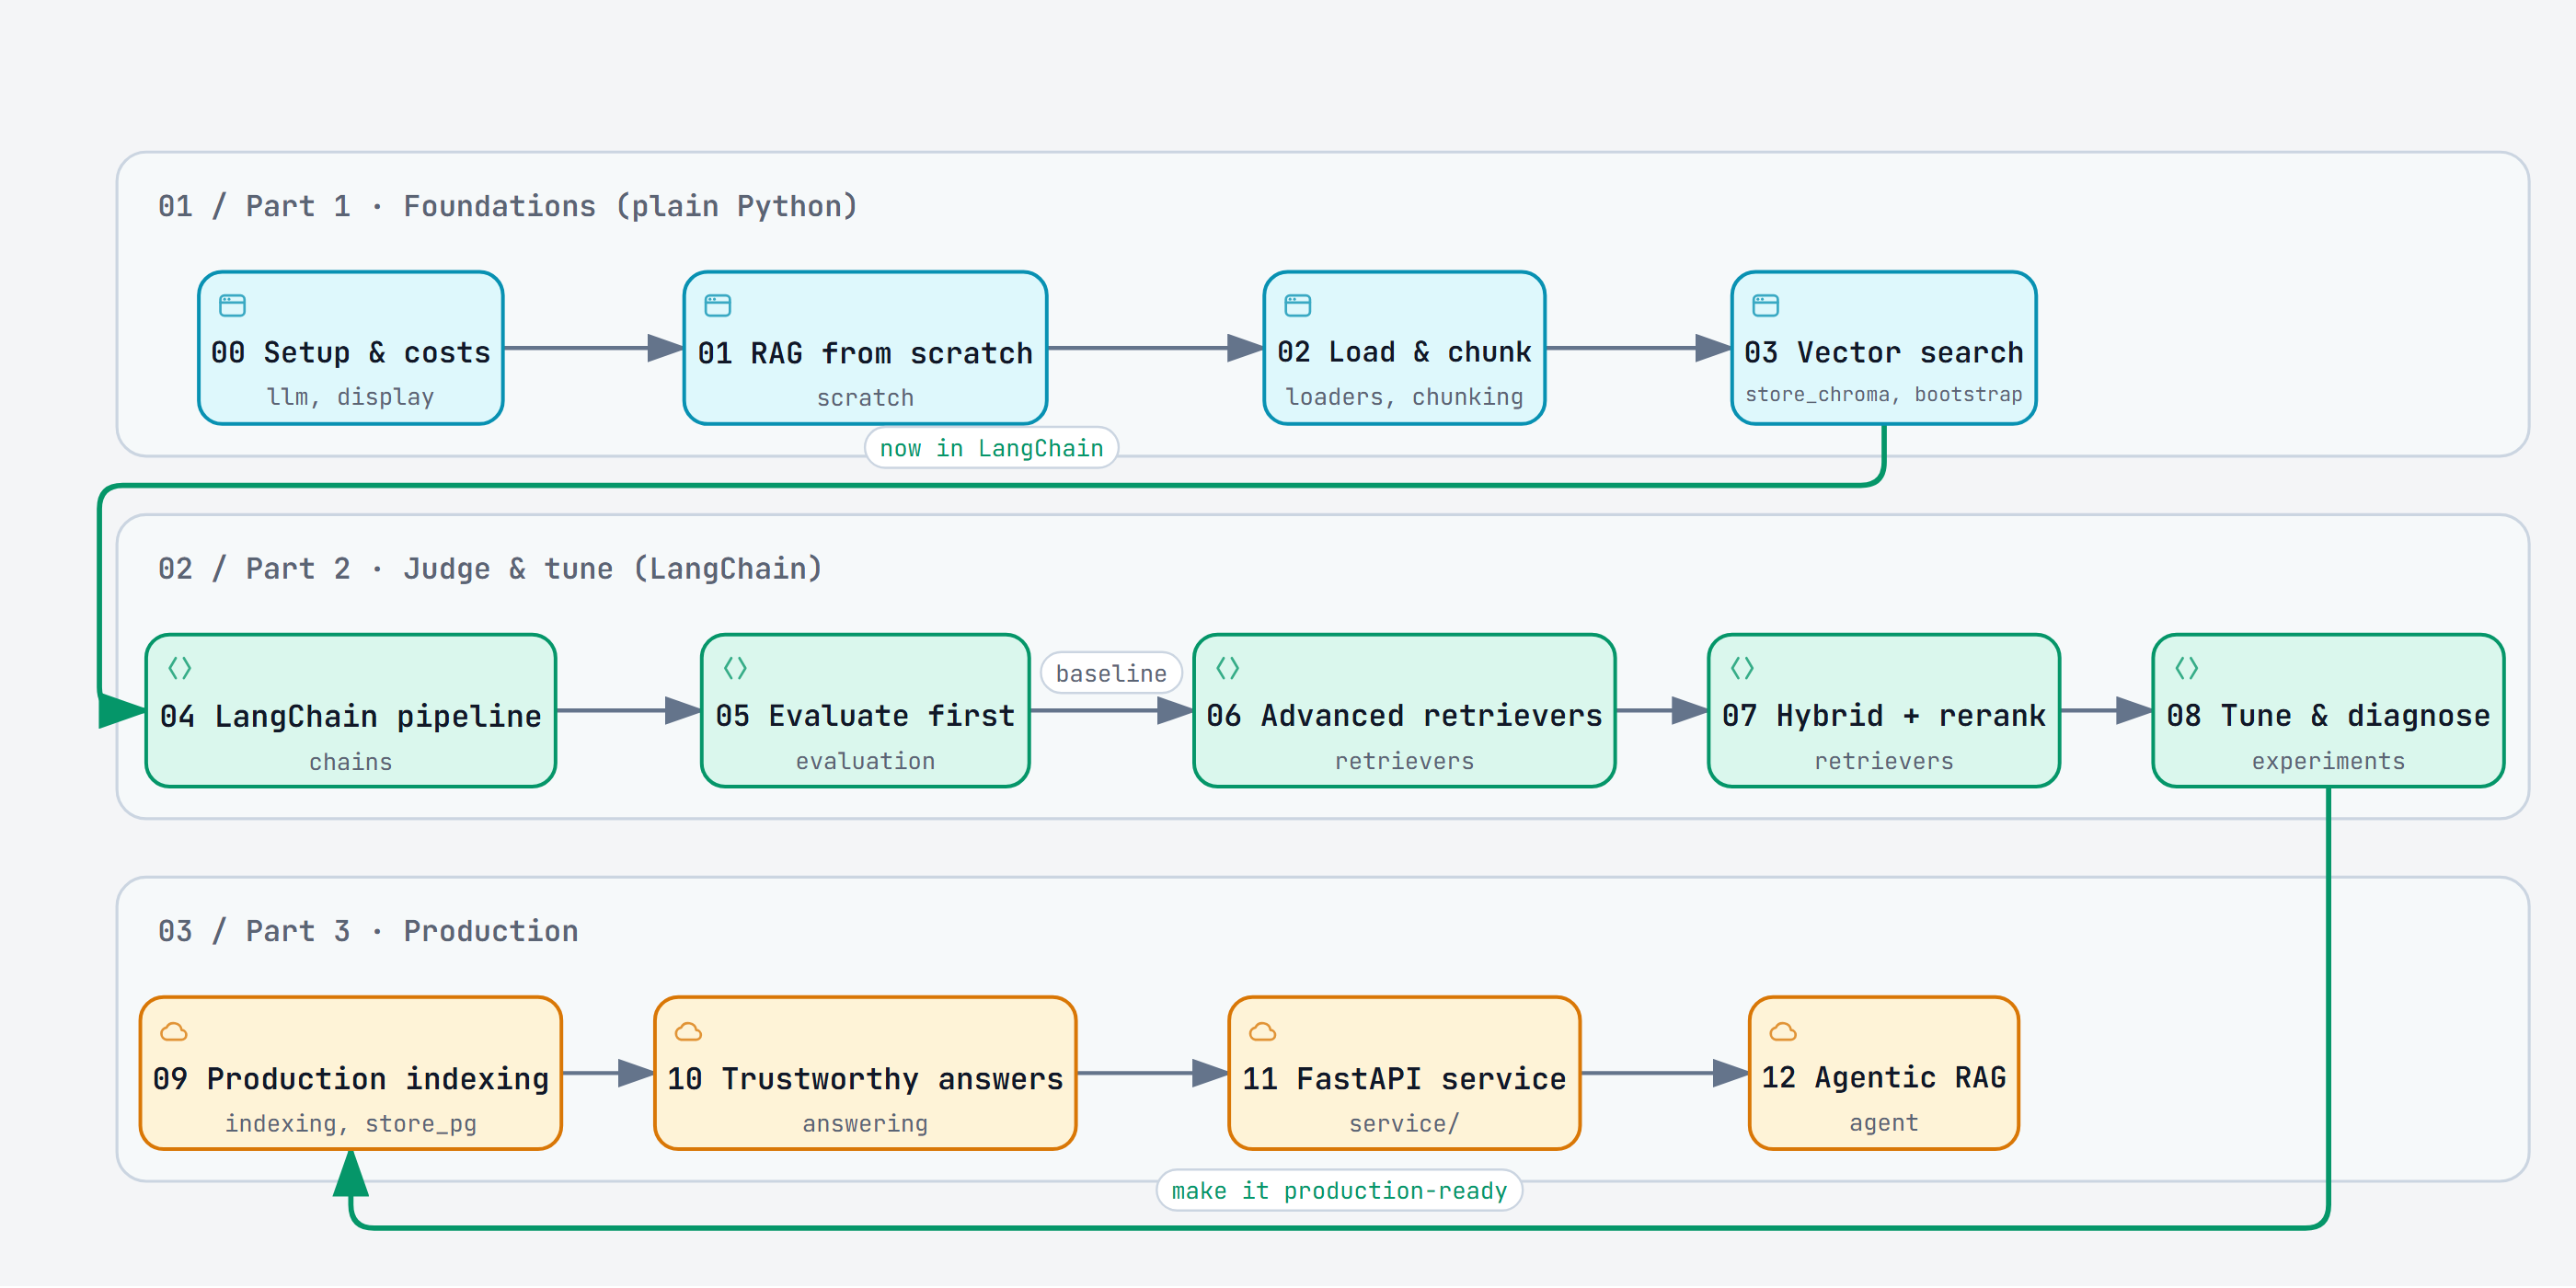

[Open interactive version](../diagrams/series_map.html)

In [12]:
show_diagram("series_map")

**One rule keeps this safe:** once a notebook adds a function to `raglab`, later notebooks never
change what it does. Improvements arrive as *new* functions or *optional* arguments. So notebook
04 behaves the same whether or not you've run notebook 09.

## Your turn

1. Ask `llm.chat()` another question about Token Hotels (for example, "Does Token Cusco have a
   pool?"). Does the model admit it doesn't know?
2. Add a fourth sentence to the similarity example that should be close to the restaurant
   sentence. Check your intuition against the numbers.
3. Use `llm.estimate_cost()` to estimate what 10,000 questions would cost with
   `gpt-5.4-mini` instead of `gpt-6-luna`.

<details><summary>Solution for 3</summary>

```python
llm.estimate_cost("gpt-5.4-mini", 10_000, 1500, 150)  # about $18.00, vs about $2.25 for gpt-6-luna
```
</details>

## Key takeaways

- RAG = retrieve relevant text, then let the model answer from it.
- Embeddings map meaning to vectors; similar meanings → similar vectors.
- The series runs on cheap models, and every notebook reports what it spent.

**Added to raglab:** `config.get_settings`, `llm.chat`, `llm.embed`, `llm.embed_one`, `llm.cost`,
`llm.estimate_cost`, `llm.check_budget`, `display.show_chunks`, `display.show_diagram`.

In [13]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                      2          35          52    0.0000
total                           2                            0.0000
